# IS6400 Assignment Week 8 — Bitcoin forecasting

LI Binxiong · 60234350

[Q1: target choice](#q1) · [Q2: level-only ETS](#q2) · [Q3: ETS with trend](#q3) · [Q4: rolling evaluation](#q4) · [Appendix A: naïve benchmark](#appendix-a)

The course tutorial is retained below, followed by the Bitcoin answers in Q1–Q4 order. All code outputs in this document are produced by running the notebook. Prices and forecast errors are measured in USD per BTC. This is an analysis of the supplied 2013–2018 dataset.


<style>
.jp-Notebook { max-width: 1080px; margin: auto; }
.jp-RenderedHTMLCommon { font-size: 18px; line-height: 1.65; color: #202733; }
.jp-RenderedHTMLCommon p { margin: 0.65em 0 0.9em; }
.jp-RenderedHTMLCommon h1 { font-size: 30px; margin-top: 1.3em; }
.jp-RenderedHTMLCommon h2 { font-size: 25px; margin-top: 1.6em; }
.jp-RenderedHTMLCommon h3 { font-size: 21px; }
.jp-RenderedHTMLCommon table { font-size: 16px; margin: 1em 0; }
.jp-RenderedHTMLCommon td, .jp-RenderedHTMLCommon th { padding: 8px 10px; }
.jp-CodeCell .jp-InputArea-editor { font-size: 14px; line-height: 1.5; }
.jp-OutputArea pre { font-size: 14px; line-height: 1.5; }
.jp-RenderedImage img, .jp-RenderedSVG svg { max-width: 100%; height: auto; }
.jp-RenderedHTMLCommon mjx-container { overflow-x: auto; overflow-y: hidden; }
@media print { .jp-RenderedHTMLCommon { font-size: 11pt; } }
.jp-RenderedHTMLCommon td:first-child { white-space: nowrap; }
.jp-RenderedImage { overflow-x: auto; }
.jp-RenderedImage img { min-width: 900px; }
@media print { .jp-RenderedImage img { min-width: 0; } }
</style>

In [1]:
from pathlib import Path
from IPython.display import display, HTML, Markdown
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import platform
import scipy
import sklearn
import statsmodels

WORK_DIR = Path.cwd().resolve()
DATA_DIR = WORK_DIR / 'data'
if not (DATA_DIR / 'Q5BTC-USD.csv').is_file():
    raise FileNotFoundError('Run this notebook from its work folder, with the data folder beside it.')
FIGURE_DIR = WORK_DIR / 'figures'
FIGURE_DIR.mkdir(exist_ok=True)


## Retained course tutorial

The shampoo and CVD examples reproduce the course sequence. The source narrative calls shampoo monthly, while the supplied CSV uses daily-looking labels and the original plots say “Daily”; its calendar frequency is therefore inconsistent across the materials. I retain the supplied order without assigning a calendar meaning to that example's period of four. Four quarters per year has a calendar meaning for CVD. These examples do not determine the model ranking for Bitcoin.


# Time Series I



This tutorial demonstrates a complete time-series forecasting workflow using Python. It introduces several classical forecasting methods, shows how to fit them with `statsmodels`, and compares their out-of-sample performance using a train/test split and RMSE.

The tutorial is intentionally structured around two datasets:

1. Shampoo sales — a monthly series with a clear upward trend but no obvious seasonality. This makes it suitable for comparing simple moving averages, simple exponential smoothing, Holt's linear trend method, and Holt-Winters.
2. Quarterly cardiovascular deaths (CVD) — a quarterly series with a repeating seasonal pattern. This makes it suitable for demonstrating why seasonal components matter and how Holt-Winters can outperform non-seasonal methods.

By the end of this tutorial, you should be able to:

- split a time series into training and test periods;
- build simple moving-average forecasts;
- fit simple exponential smoothing, Holt linear trend, and Holt-Winters models using `ETSModel`;
- interpret the role of error, trend, and seasonal components in an ETS model;
- evaluate forecasts using RMSE;
- compare models and explain why a more complex model is not always better.

The main evaluation metric used here is root mean squared error:

$$
\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_{t=1}^{n}(y_t-\hat y_t)^2}
$$

Lower RMSE indicates better forecast performance on the chosen test set. 

### About this tutorial

This tutorial accompanies the Week 8 slides and provides Python examples for solving time-series forecasting problems. You should refer to the Week 8 slides to understand the key concepts introduced here.

### The `statsmodels` toolbox

`statsmodels` is a Python library that provides classes and functions for estimating many different statistical models, conducting statistical tests, and exploring statistical data.

The key tool used in this tutorial is the ETS model from `statsmodels.tsa.exponential_smoothing.ets`. An ETS model has three components:

- E — error type (additive or multiplicative);
- T — trend type (additive, multiplicative, damped, or none);
- S — seasonality type (additive, multiplicative, or none).

By setting the `trend` and `seasonal` arguments, the same `ETSModel` class can represent simple exponential smoothing, Holt's linear trend method, and Holt-Winters.

Reference: <https://www.statsmodels.org/devel/generated/statsmodels.tsa.exponential_smoothing.ets.ETSModel.html>

In [2]:
import pandas as pd
import numpy as np
from sklearn import metrics
from statsmodels.tsa.exponential_smoothing.ets import ETSModel #key library
from matplotlib import pyplot as plt
# a magic function that renders the figure in a notebook
%matplotlib inline

pd.options.mode.chained_assignment = None 

## 1. Shampoo sales



In [3]:
# read csv file
shampoo = pd.read_csv(DATA_DIR / 'shampoo_sales.csv')
shampoo.head()

,Date,Sales
0,1/1/2020,266.0
1,2/1/2020,145.9
2,3/1/2020,183.1
3,4/1/2020,119.3
4,5/1/2020,180.3


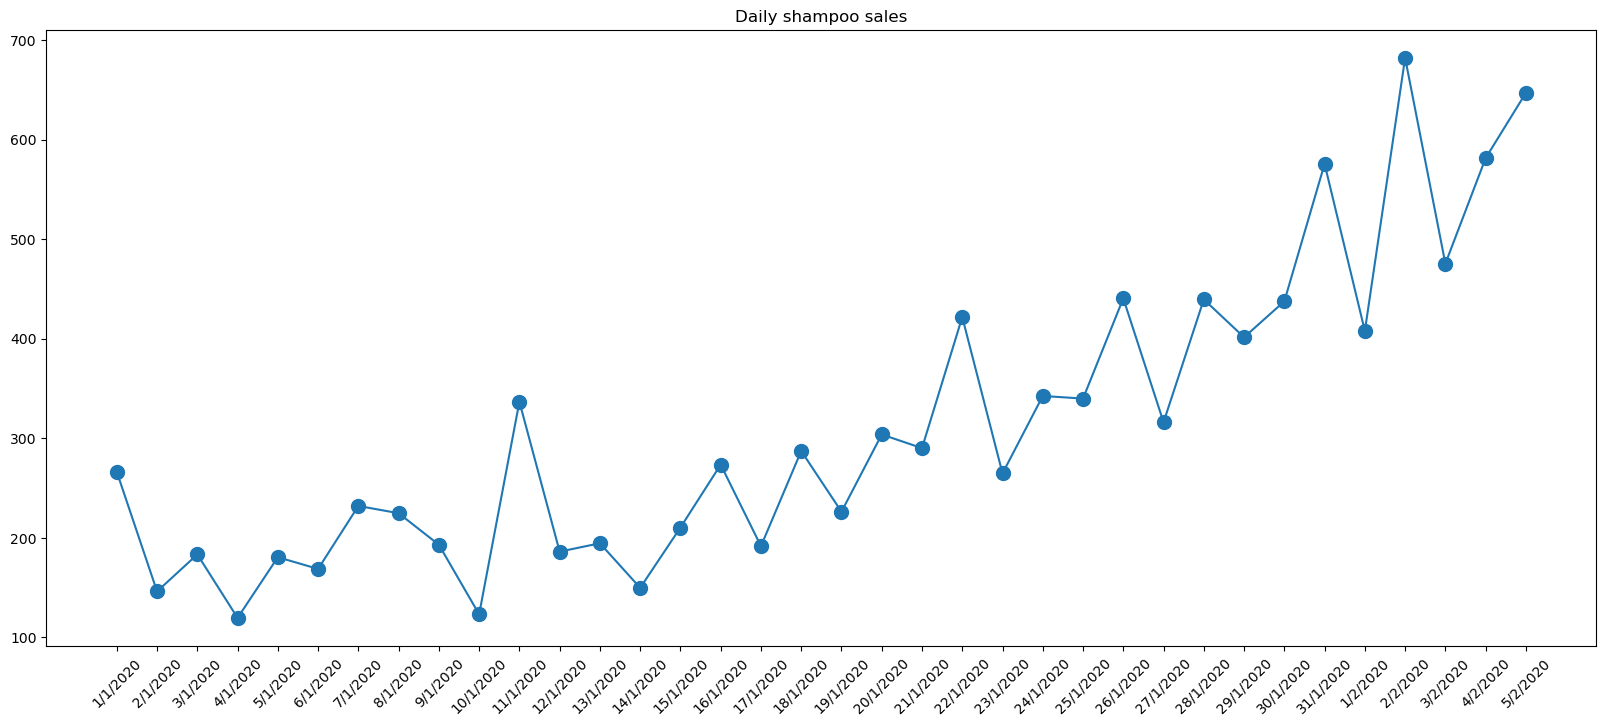

In [4]:
# plot the time series data
plt.figure(figsize = (20,8))
plt.plot(shampoo['Date'], shampoo['Sales'], '.-', markersize=20)
plt.title('Daily shampoo sales')
plt.xticks(rotation=45) # 👈 Add this line to rotate dates by 45 degrees
plt.show()

### Do you observe any trend or seasonality?

Observation. There is a clear upward trend but no obvious seasonality. A Holt linear model (exponential smoothing + trend) may therefore be appropriate. But we will try several different models anyway as benchmarks: moving average, simple exponential smoothing, Holt linear, and Holt-Winters.

Comparing these models on the same test set makes it possible to see which components — trend and/or seasonality — actually help.

In [5]:
# first split our data into training and test
train = shampoo[:-5] #"-5 index" means the last five records in this list.
test = shampoo[-5:]
train.shape, test.shape #first 31 records are used for training and the rest for testing

((31, 2), (5, 2))

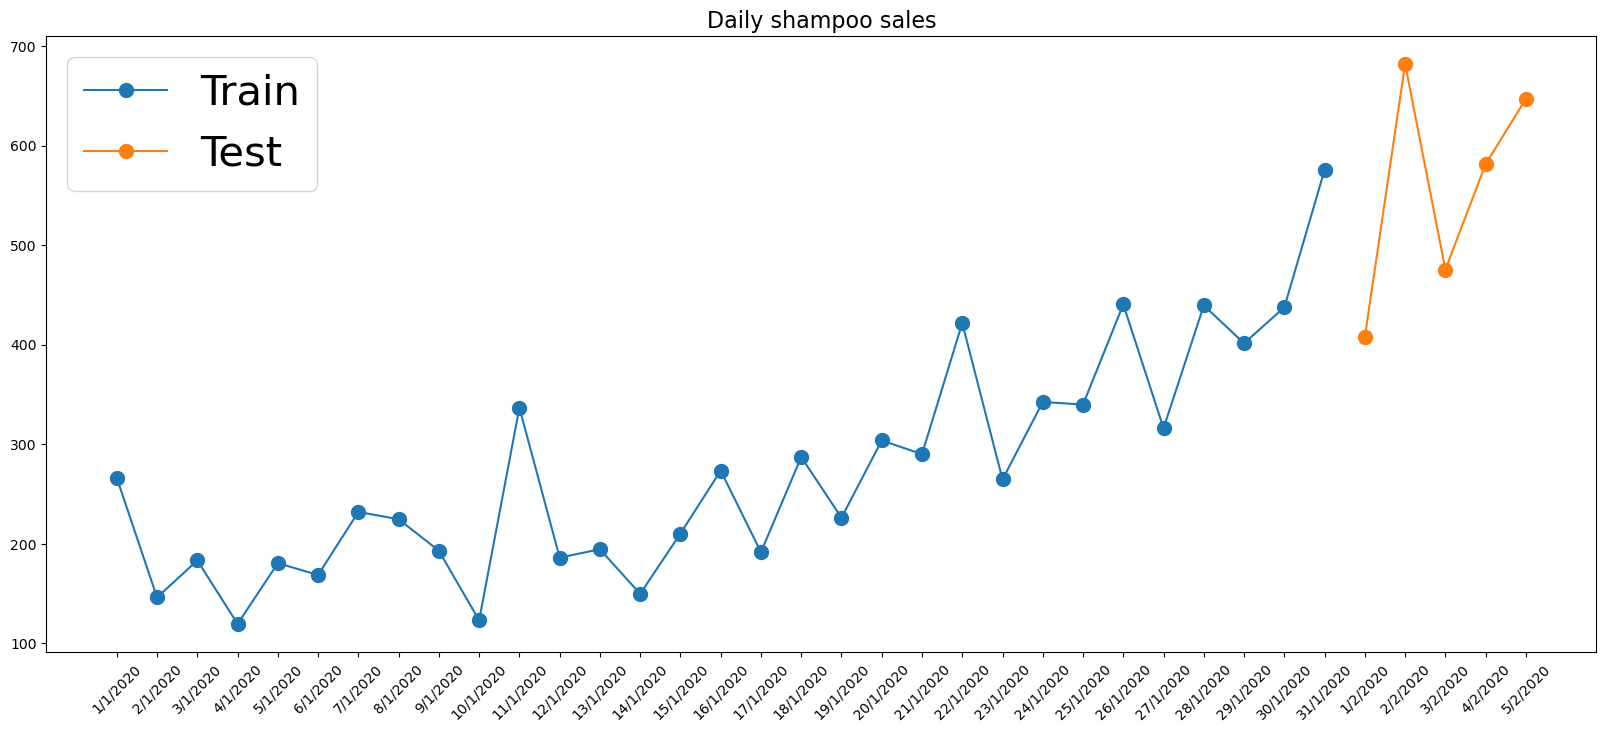

In [6]:
# plot training and testing data
plt.figure(figsize = (20,8))
plt.plot(train['Date'], train['Sales'], '.-',markersize=20,label = 'Train')
plt.plot(test['Date'], test['Sales'], '.-',markersize=20,label = 'Test')
plt.legend(loc = 'upper left',fontsize=30)
plt.title('Daily shampoo sales',fontsize=16)
plt.xticks(rotation=45) # 👈 Add this line to rotate dates by 45 degrees
plt.show()

### 1.1 Simple moving average

A simple moving average forecasts by averaging the most recent $w$ observations. In the tutorial, the forecast for the test period is the last available rolling average, held constant across the forecast horizon.

A moving average is a useful baseline, but it does not extrapolate a trend. If the series is rising, a flat moving-average forecast will tend to under-predict future values. The window size controls smoothness: a small window reacts faster but is noisier; a large window is smoother but reacts more slowly. The RMSE comparison below shows that the 5-window moving average performs best among the three moving-average benchmarks.

#### 1.1.1 window size of 5

In [7]:
#we can simply using the rolling window to calculate the moving average of this data
train['moving_average_5']=train['Sales'].rolling(5).mean() #window size of 5
train.head(31)

,Date,Sales,moving_average_5
0,1/1/2020,266.0,NaN
1,2/1/2020,145.9,NaN
2,3/1/2020,183.1,NaN
3,4/1/2020,119.3,NaN
4,5/1/2020,180.3,178.92
5,6/1/2020,168.5,159.42
6,7/1/2020,231.8,176.60
7,8/1/2020,224.5,184.88
8,9/1/2020,192.8,199.58
9,10/1/2020,122.9,188.10


In [8]:
#then we use the last window average as predicted value
test.loc[:,'moving_average_forecast_5'] = train['moving_average_5'].iloc[-1]
test.head()

,Date,Sales,moving_average_forecast_5
31,1/2/2020,407.6,433.88
32,2/2/2020,682.0,433.88
33,3/2/2020,475.3,433.88
34,4/2/2020,581.3,433.88
35,5/2/2020,646.9,433.88


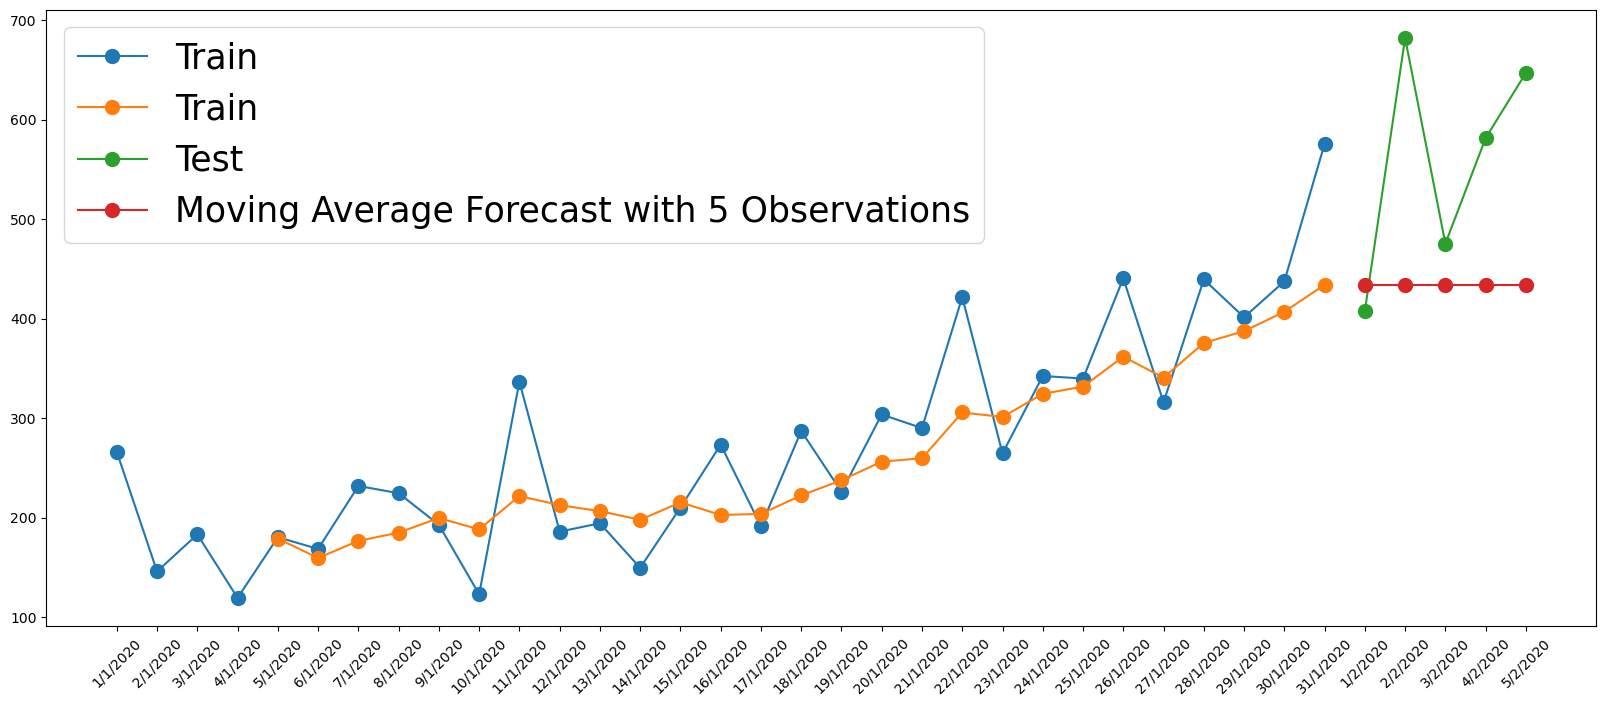

In [9]:

plt.figure(figsize = (20,8))
plt.plot(train['Date'], train['Sales'], '.-',markersize=20, label = 'Train')
plt.plot(train['Date'], train['moving_average_5'], '.-',markersize=20, label = 'Train')
plt.plot(test['Date'], test['Sales'],'.-',markersize=20, label = 'Test')
plt.plot(test['Date'], test['moving_average_forecast_5'],'.-',markersize=20, label = 'Moving Average Forecast with 5 Observations')
plt.legend(loc = 'upper left',fontsize=25)
plt.xticks(rotation=45) # 👈 Add this line to rotate dates by 45 degrees
plt.show()

#### 1.1.1 window size of 10

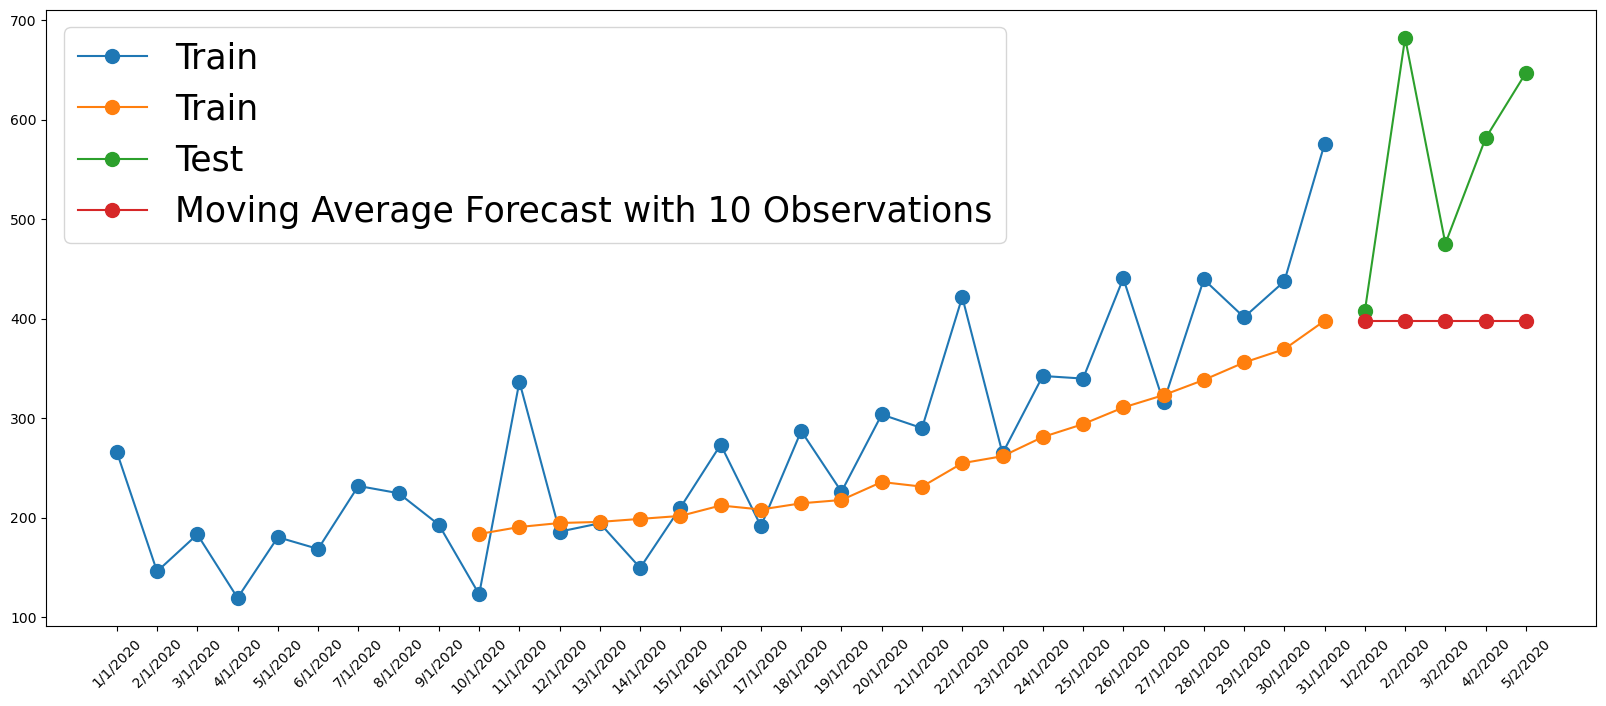

In [10]:
#let's switching to a moving window of size 10
train['moving_average_10']=train['Sales'].rolling(10).mean()
test['moving_average_forecast_10'] = train['moving_average_10'].iloc[-1]
plt.figure(figsize = (20,8))
plt.plot(train['Date'], train['Sales'], '.-',markersize=20, label = 'Train')
plt.plot(train['Date'], train['moving_average_10'], '.-',markersize=20, label = 'Train')
plt.plot(test['Date'], test['Sales'],'.-',markersize=20, label = 'Test')
plt.plot(test['Date'], test['moving_average_forecast_10'],'.-',markersize=20, label = 'Moving Average Forecast with 10 Observations')
plt.legend(loc = 'upper left',fontsize=25)
plt.xticks(rotation=45) # 👈 Add this line to rotate dates by 45 degrees
plt.show()

#### 1.1.1 window size of 15

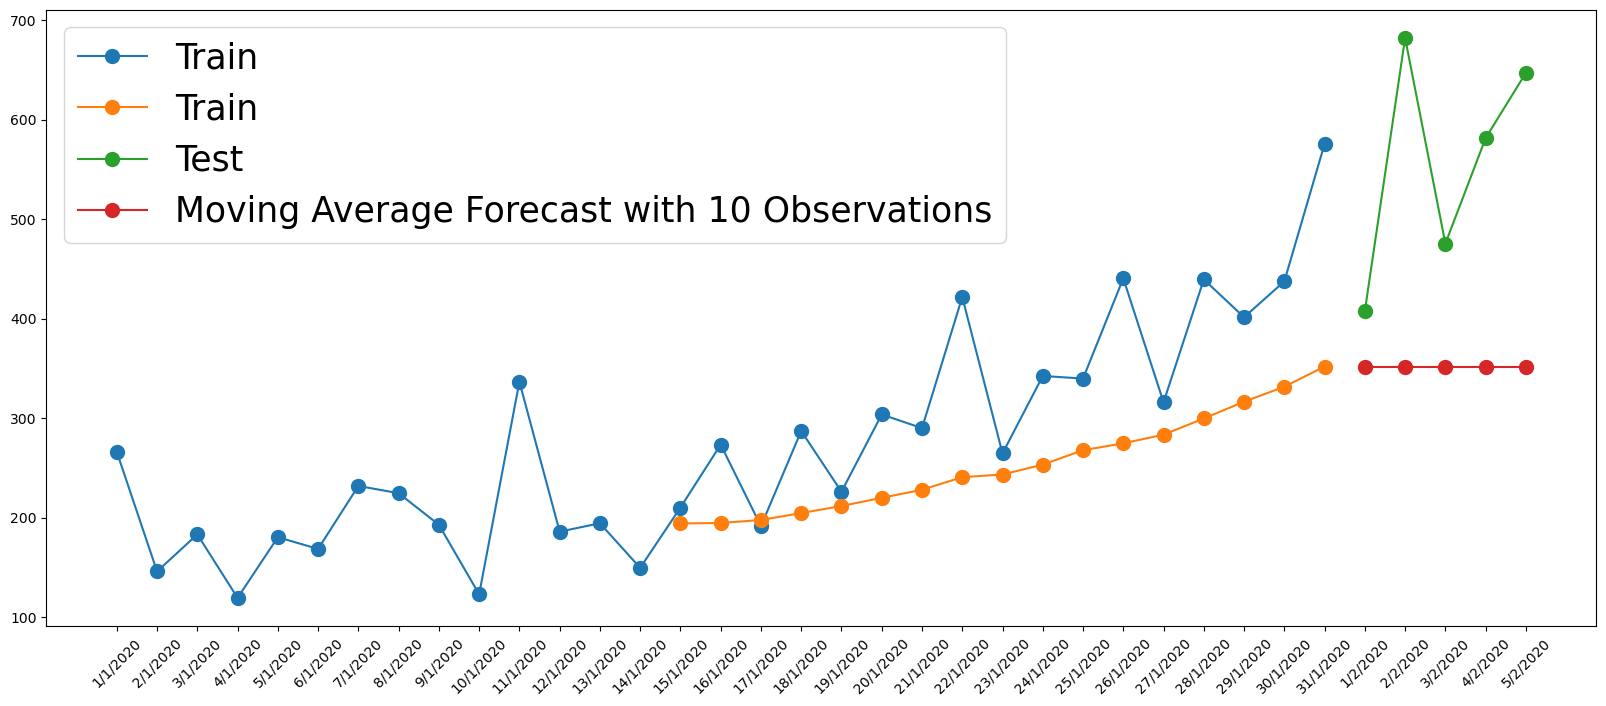

In [11]:
#let's switching to a moving window of size 15
train['moving_average_15']=train['Sales'].rolling(15).mean()
test['moving_average_forecast_15'] = train['moving_average_15'].iloc[-1]
plt.figure(figsize = (20,8))
plt.plot(train['Date'], train['Sales'], '.-',markersize=20, label = 'Train')
plt.plot(train['Date'], train['moving_average_15'], '.-',markersize=20, label = 'Train')
plt.plot(test['Date'], test['Sales'],'.-',markersize=20, label = 'Test')
plt.plot(test['Date'], test['moving_average_forecast_15'],'.-',markersize=20, label = 'Moving Average Forecast with 10 Observations')
plt.legend(loc = 'upper left',fontsize=25)
plt.xticks(rotation=45) # 👈 Add this line to rotate dates by 45 degrees
plt.show()

#### 1.1.4 Evaluation of different moving-average forecast

In [12]:
# get rmse of moving average with 5, 10, and 15 windows on test data
rmse_sma5 = np.sqrt(metrics.mean_squared_error(y_pred=test['moving_average_forecast_5'],
                                               y_true=test['Sales']))
rmse_sma10 = np.sqrt(metrics.mean_squared_error(y_pred=test['moving_average_forecast_10'],
                                                y_true=test['Sales']))
rmse_sma15 = np.sqrt(metrics.mean_squared_error(y_pred=test['moving_average_forecast_15'],
                                                y_true=test['Sales']))
print(rmse_sma5)
print(rmse_sma10)
print(rmse_sma15)

161.91353618521214
191.1078609058246
231.22183201419364


- Interpretation of the moving-average RMSE results

    - While the moving average with 5-window size achieves the best performance among the three moving-average benchmarks, the overall performance is not very good. This is because a moving average does not capture trend patterns — it simply smooths the series and repeats a past average.

    - This motivates moving to exponential smoothing methods, which weight recent observations more heavily and can be extended with trend and seasonal components.

### 1.2 Simple exponential smoothing

Simple exponential smoothing (SES) estimates a level component only. It is appropriate when the series has no clear trend or seasonality. Because it has no trend term, its forecast is flat.

On the shampoo data, SES improves on the moving-average benchmarks but still cannot capture the upward trend. This is expected: SES deliberately omits the trend.

In [13]:
ses = ETSModel(train['Sales']) #by default, it is SEM
ses_fit = ses.fit(disp=False)
y_predict = ses_fit.forecast(5)

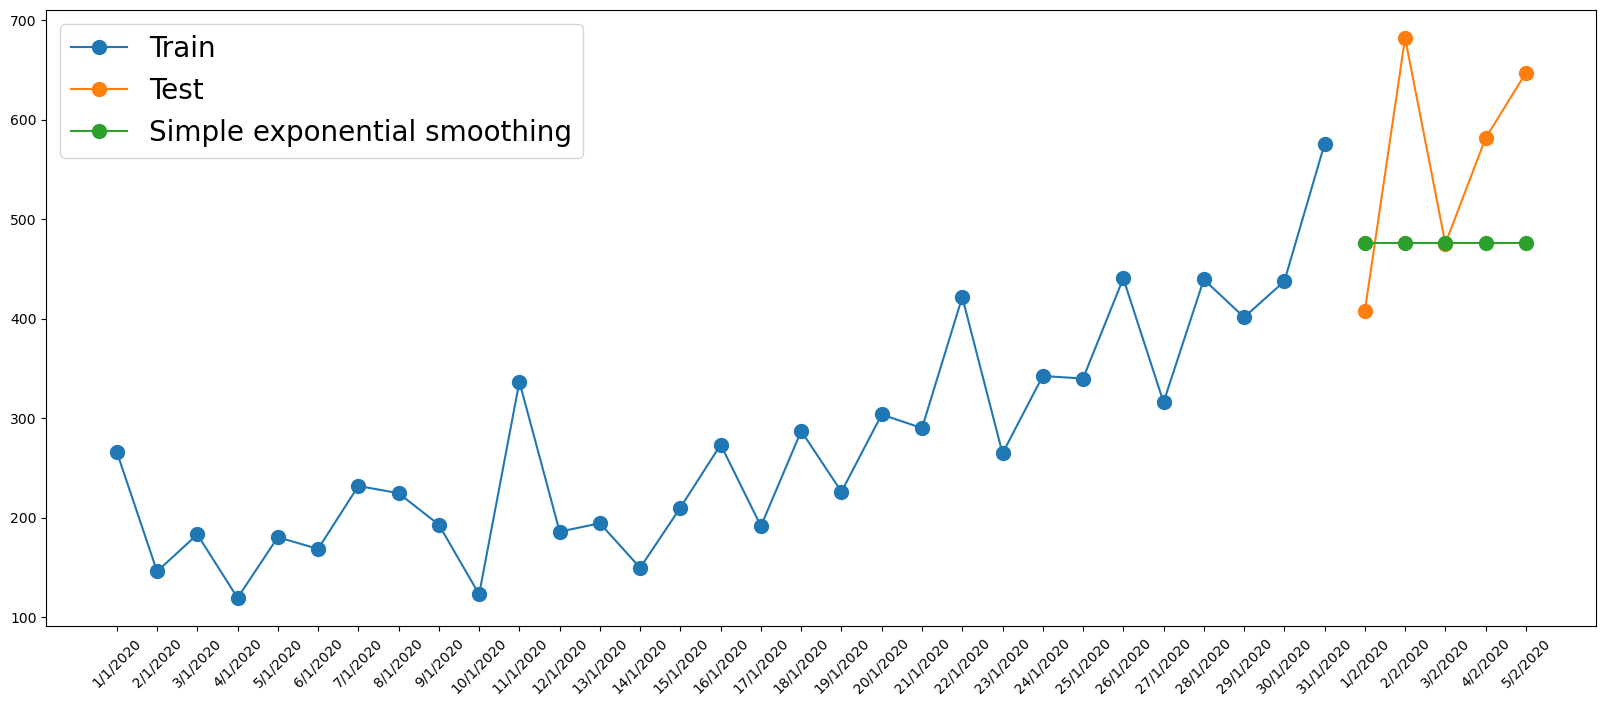

In [14]:
plt.figure(figsize = (20,8))
plt.plot(train['Date'], train['Sales'],'.-',markersize=20, label = 'Train')
plt.plot(test['Date'], test['Sales'],'.-',markersize=20, label = 'Test')
plt.plot(test['Date'], y_predict,'.-',markersize=20, label = 'Simple exponential smoothing')
plt.legend(loc = 'upper left',fontsize=20)
plt.xticks(rotation=45) # 👈 Add this line to rotate dates by 45 degrees
plt.show()

In [15]:
rmse_ses = np.sqrt(metrics.mean_squared_error(y_pred=y_predict, y_true=test['Sales']))
print(rmse_ses)

132.54466580642148


### 1.3 Holt linear trend

Holt's linear method adds a trend component to simple exponential smoothing. This is well matched to the shampoo series, which has a clear upward trend.

In the tutorial, setting `trend='add'` allows the forecast to continue the estimated trend rather than remaining flat. Holt therefore achieves the lowest RMSE on the shampoo test set among the models considered so far.

In [16]:
holt = ETSModel(train['Sales'], trend='add') #we use linear by adding addictive trend pattern
holt_fit = holt.fit(disp=False)
y_predict = holt_fit.forecast(5)

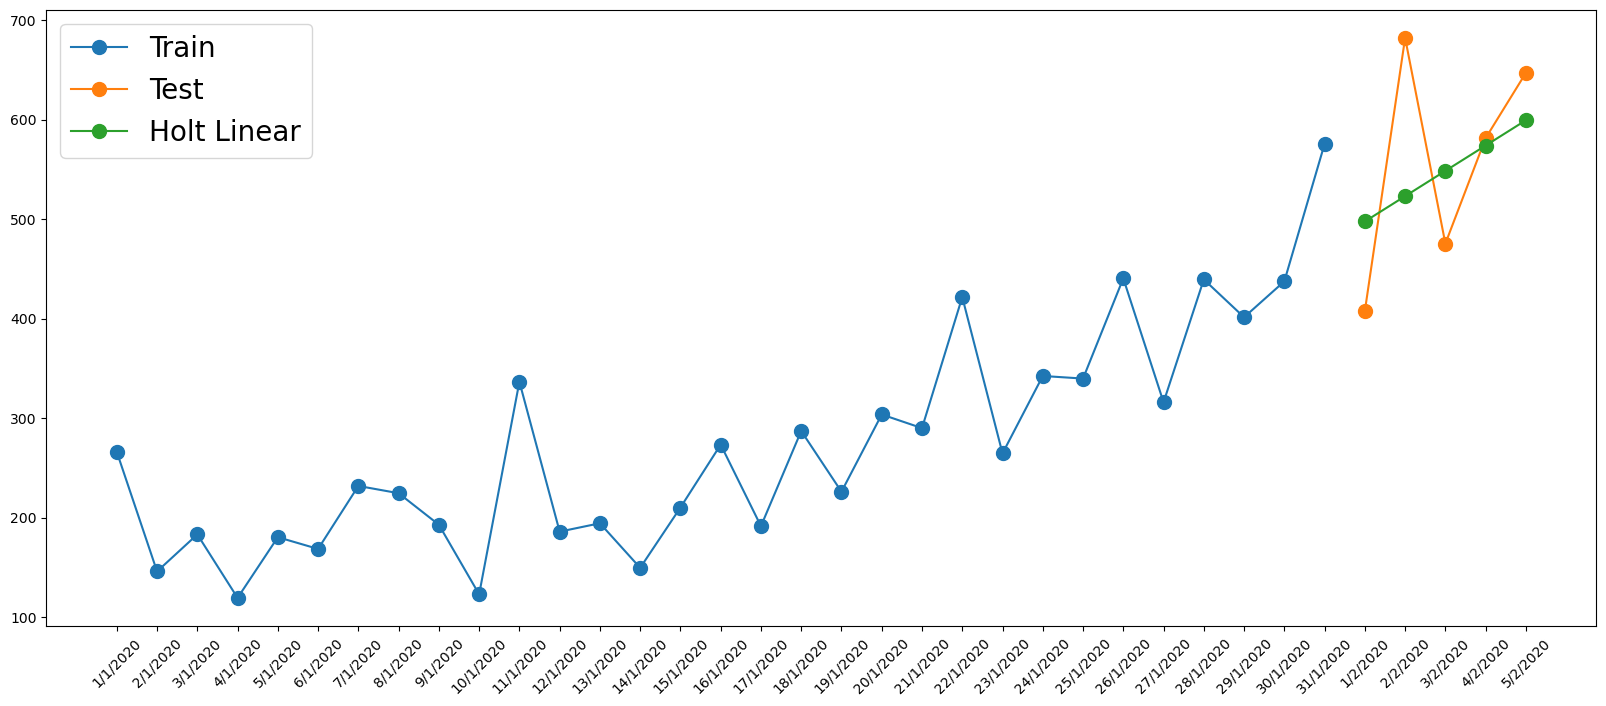

In [17]:
plt.figure(figsize = (20,8))
plt.plot(train['Date'], train['Sales'],'.-',markersize=20, label = 'Train')
plt.plot(test['Date'], test['Sales'],'.-',markersize=20, label = 'Test')
plt.plot(test['Date'], y_predict,'.-',markersize=20, label = 'Holt Linear')
plt.legend(loc = 'upper left',fontsize=20)
plt.xticks(rotation=45) # 👈 Add this line to rotate dates by 45 degrees
plt.show()

In [18]:
rmse_holt = np.sqrt(metrics.mean_squared_error(y_pred=y_predict, y_true=test['Sales']))
print(rmse_holt)

90.60628513553894


### 1.4 Holt-Winters

Holt-Winters adds a seasonal component to Holt's linear trend. In the tutorial, `seasonal='add'` and `seasonal_periods=4` are used to illustrate a seasonal ETS model.

However, the shampoo series does not show clear seasonality. Adding a seasonal component therefore does not improve the forecast and can make the model unnecessarily complex. This illustrates an important modelling principle: only include a seasonal component when the data show a genuine seasonal pattern.

In [19]:
holt = ETSModel(train['Sales'], trend='add',seasonal = 'add', seasonal_periods = 4) 
holt_fit = holt.fit(disp=False)
y_predict = holt_fit.forecast(5)

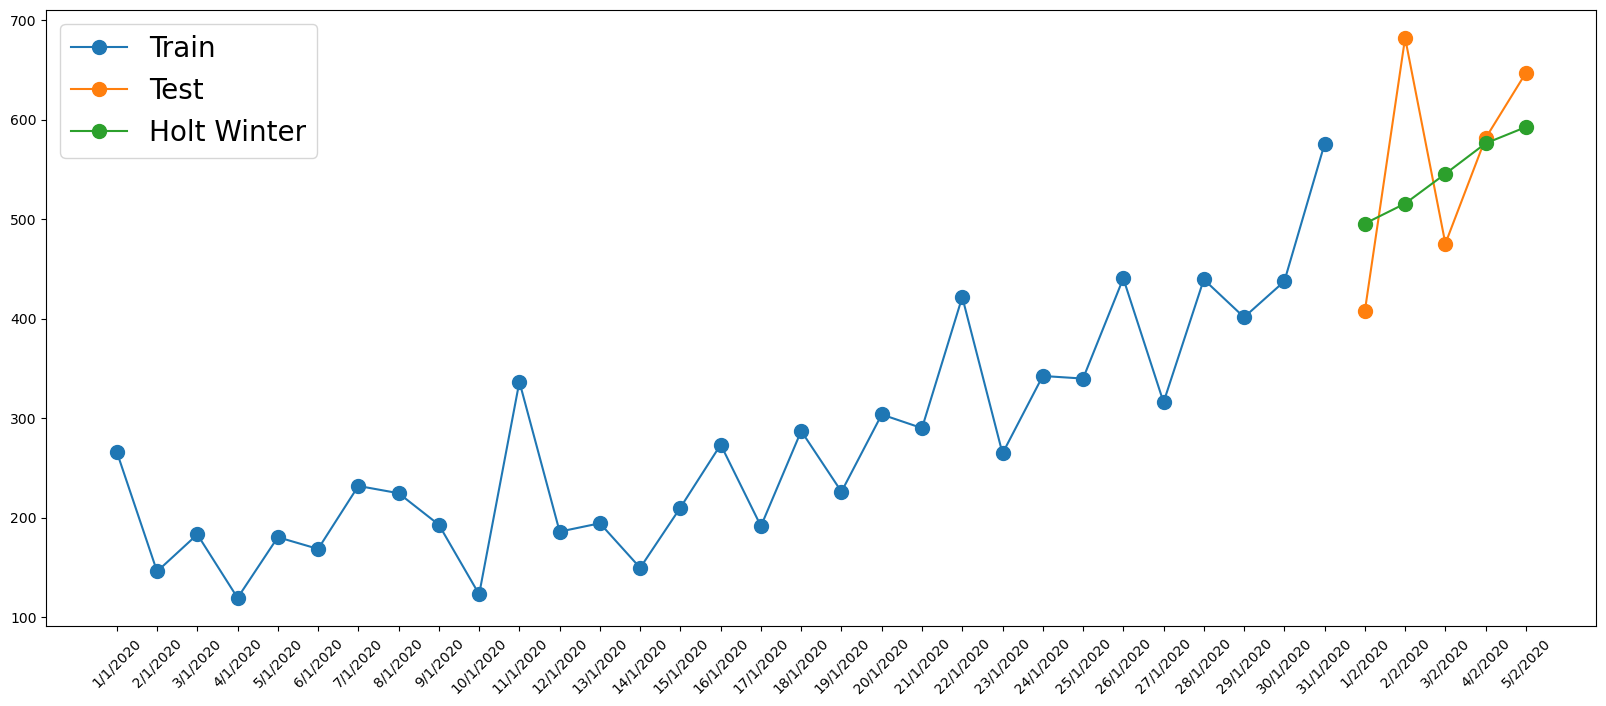

In [20]:
plt.figure(figsize = (20,8))
plt.plot(train['Date'], train['Sales'],'.-',markersize=20, label = 'Train')
plt.plot(test['Date'], test['Sales'],'.-',markersize=20, label = 'Test')
plt.plot(test['Date'], y_predict,'.-',markersize=20, label = 'Holt Winter')
plt.legend(loc = 'upper left',fontsize=20)
plt.xticks(rotation=45) # 👈 Add this line to rotate dates by 45 degrees
plt.show()

In [21]:
rmse_holt = np.sqrt(metrics.mean_squared_error(y_pred=y_predict, y_true=test['Sales']))
print(rmse_holt)

93.09741901213341


## 2. Quarterly cardiovascular deaths (CVD)

The CVD series is quarterly, so a natural seasonal period is 4. Unlike the shampoo data, the CVD plot shows a repeating within-year pattern. This makes the CVD data a good example for comparing non-seasonal and seasonal exponential smoothing models.

The tutorial fits:

- simple exponential smoothing — no trend, no seasonality;
- Holt linear trend — adds a trend component;
- Holt-Winters — adds both trend and additive seasonality.

The RMSE results show the expected pattern: simple exponential smoothing performs worst because it ignores both trend and seasonality; Holt linear improves slightly; Holt-Winters improves substantially because it captures the quarterly seasonal pattern.

In [22]:
# import the data
cvd = pd.read_csv(DATA_DIR / 'CVD.csv')
cvd.head()

,year,quarter,cvd
0,1987,1,4761
1,1987,2,4217
2,1987,3,3950
3,1987,4,4639
4,1988,1,5354


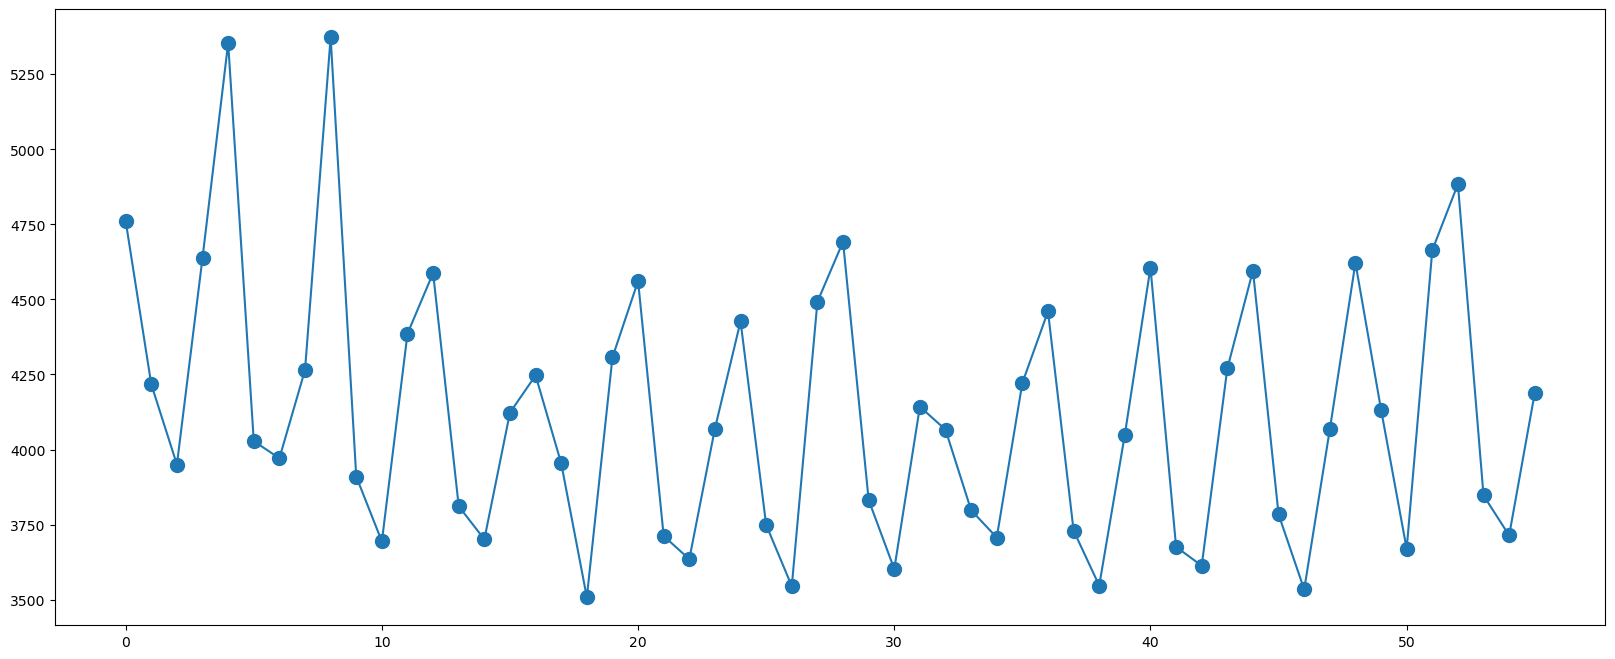

In [23]:
# plot the data
plt.figure(figsize = (20,8))
plt.plot(cvd['cvd'],'.-',markersize=20)
plt.show()

### Let us try different exponential smoothing methods

We now split the CVD data into 90% training and 10% testing, then fit three ETS variants. By comparing RMSE across the three models, we can see the effect of adding trend and seasonal components.

In [24]:
# let's first split our data into 90% training and 10% testing
N_train = int(0.9*cvd.shape[0])
N_test = cvd.shape[0] - N_train
print(N_train)
print(N_test)

50
6


In [25]:
cvd_train = cvd[:N_train] # take first N_train (50) data as trainig data
cvd_test = cvd[N_train:] # the remaining N_test (6) data as test data

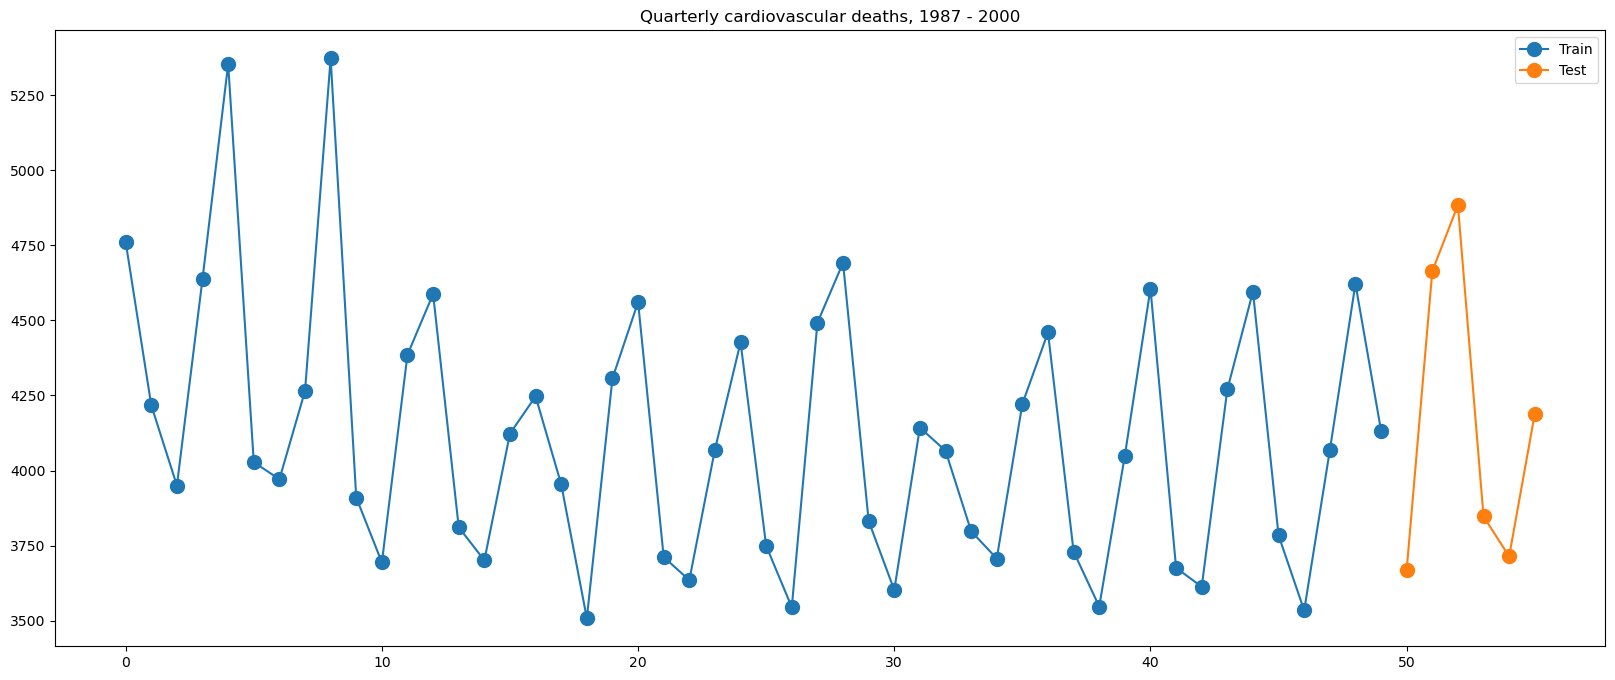

In [26]:
plt.figure(figsize = (20,8))
plt.plot(cvd_train['cvd'],'.-',markersize=20, label = 'Train')
plt.plot(cvd_test['cvd'],'.-',markersize=20, label = 'Test')
plt.legend(loc = 'upper right')
plt.title('Quarterly cardiovascular deaths, 1987 - 2000')
plt.show()

### 2.1 Simple exponential smoothing

As a baseline, we fit simple exponential smoothing. On a seasonal series, a flat forecast is clearly inadequate: it ignores the repeating quarterly pattern and produces a high RMSE.

In [27]:
ses = ETSModel(cvd_train['cvd']) 
ses_fit = ses.fit(disp=False)
y_predict = ses_fit.forecast(N_test)

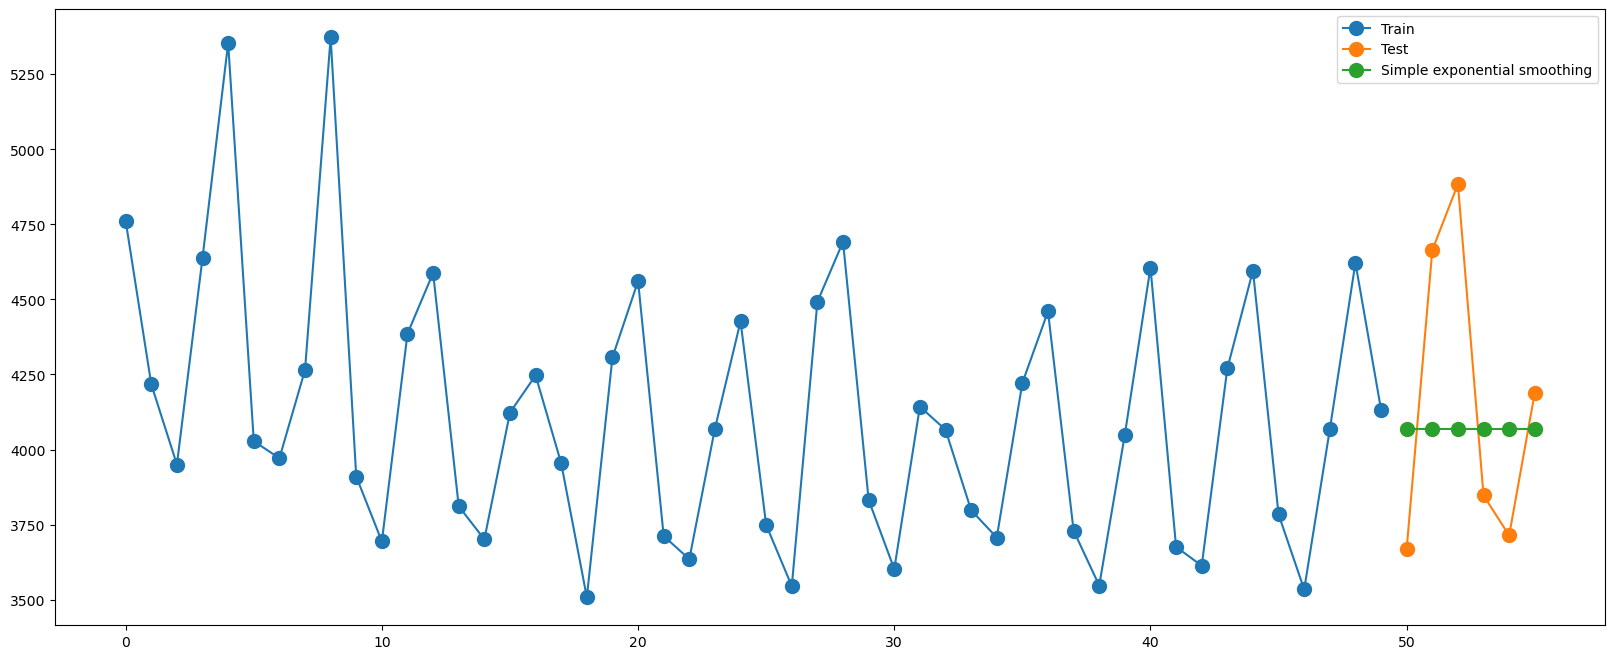

In [28]:
plt.figure(figsize = (20,8))
plt.plot(cvd_train['cvd'],'.-',markersize=20, label = 'Train')
plt.plot(cvd_test['cvd'],'.-',markersize=20, label = 'Test')
plt.plot(y_predict,'.-',markersize=20, label = 'Simple exponential smoothing')
plt.legend(loc = 'upper right')
plt.show()

In [29]:
rmse_ses = np.sqrt(metrics.mean_squared_error(y_pred=y_predict, y_true=cvd_test['cvd']))
print(rmse_ses)

477.630289222993


### 2.2 Holt linear

Holt's linear method adds a trend component. On the CVD data, the trend is relatively mild, so the improvement over simple exponential smoothing is modest. The seasonal pattern is still not captured, which limits the accuracy of the forecast.

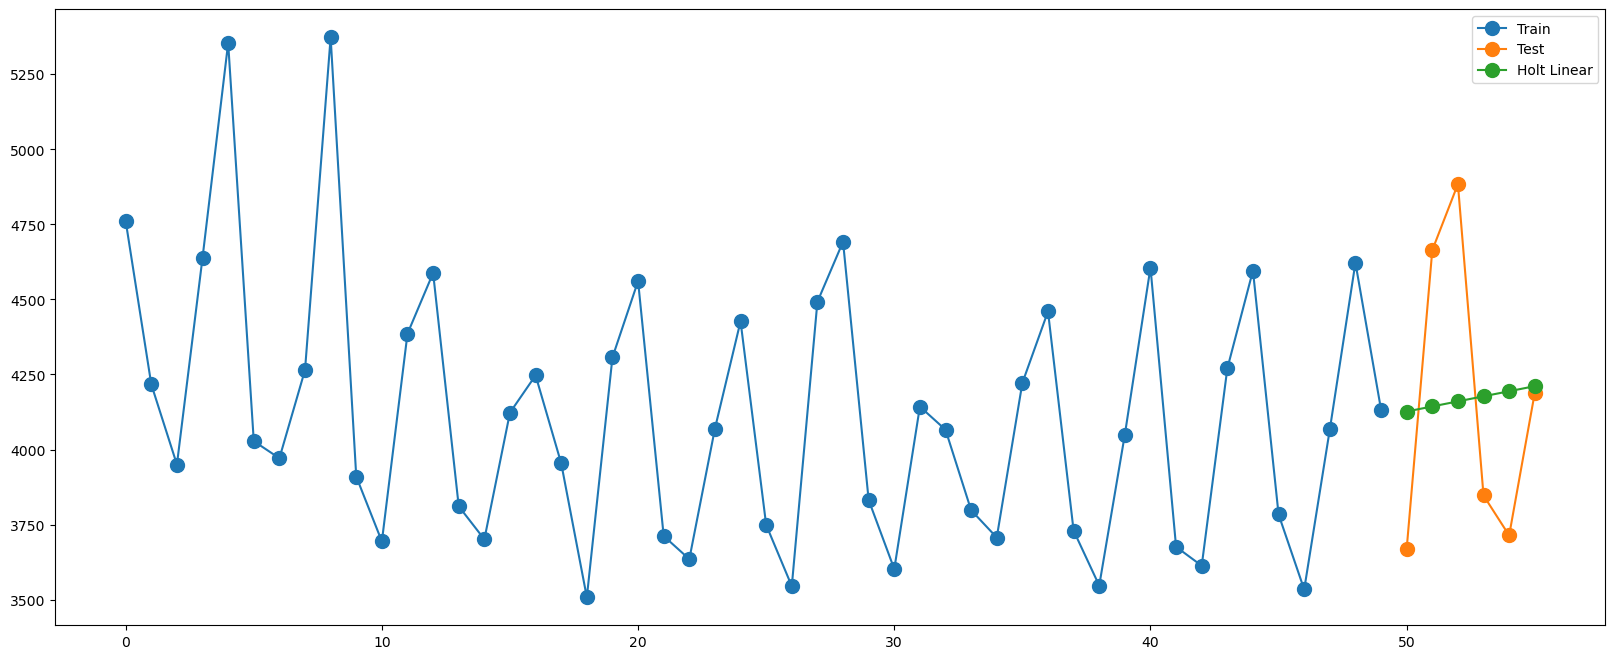

473.29664366692185


In [30]:
ses = ETSModel(cvd_train['cvd'], trend='add') 
ses_fit = ses.fit(disp=False)
y_predict = ses_fit.forecast(N_test)

plt.figure(figsize = (20,8))
plt.plot(cvd_train['cvd'],'.-',markersize=20, label = 'Train')
plt.plot(cvd_test['cvd'],'.-',markersize=20, label = 'Test')
plt.plot(y_predict,'.-',markersize=20, label = 'Holt Linear')
plt.legend(loc = 'upper right')
plt.show()

rmse_ses = np.sqrt(metrics.mean_squared_error(y_pred=y_predict, y_true=cvd_test['cvd']))
print(rmse_ses)

### 2.3 Holt-Winters

Holt-Winters adds both trend and additive seasonal components. On the CVD data, this captures the repeating quarterly pattern and produces a much lower RMSE than the non-seasonal methods. This is the expected outcome: the CVD series has a clear seasonal pattern, so a seasonal model is appropriate.

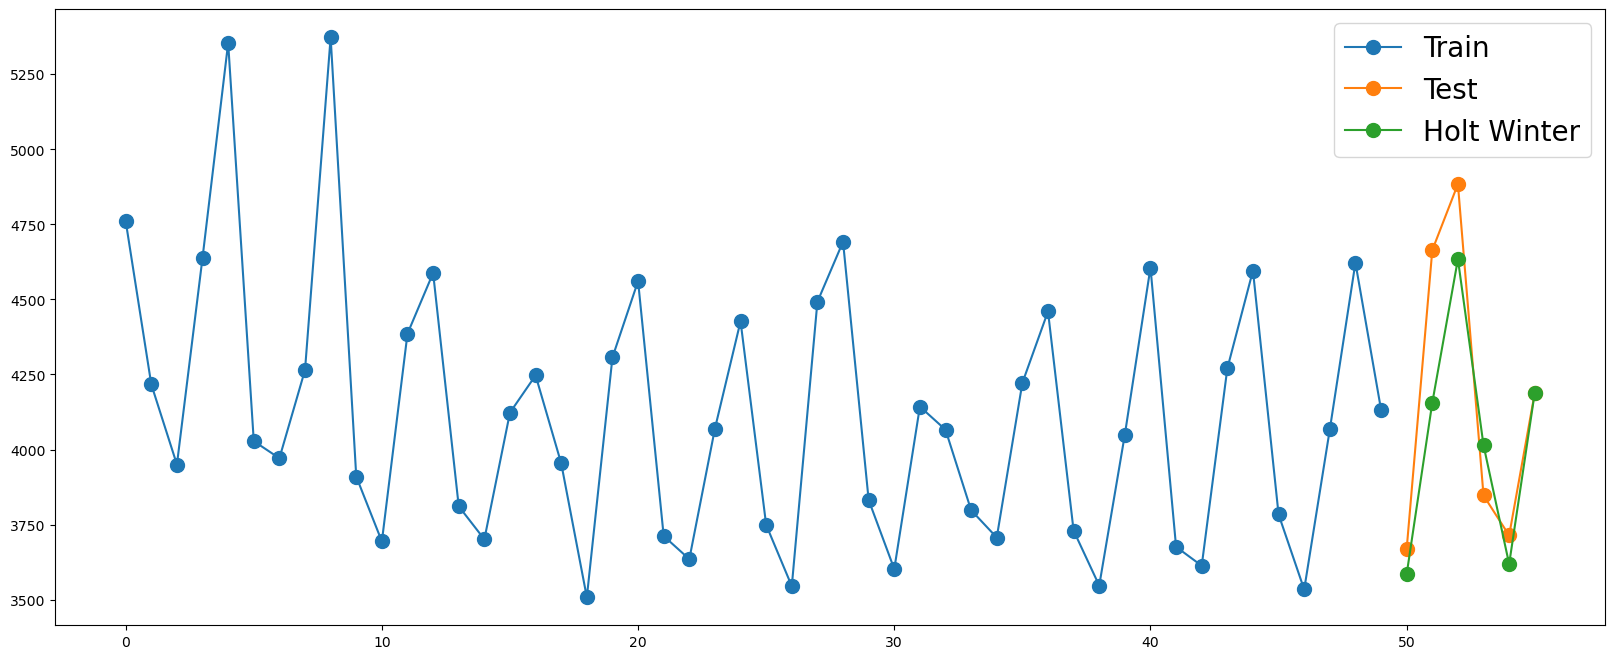

246.58432147396323


In [31]:
hw = ETSModel(cvd_train['cvd'], trend='add', seasonal = 'add', seasonal_periods = 4)
hw_fit = hw.fit(disp=False)
y_predict = hw_fit.forecast(N_test)

plt.figure(figsize = (20,8))
plt.plot(cvd_train['cvd'],'.-',markersize=20, label = 'Train')
plt.plot(cvd_test['cvd'],'.-',markersize=20, label = 'Test')
plt.plot(y_predict,'.-',markersize=20, label = 'Holt Winter')
plt.legend(loc = 'upper right',fontsize=20)
plt.show()

rmse_hw = np.sqrt(metrics.mean_squared_error(y_pred=y_predict, y_true=cvd_test['cvd']))
print(rmse_hw)

# Assignment Week 8 

Bitcoin is a cryptocurrency. Its price has increased dramatically in the past five years. The file `Q5BTC-USD.csv` contains Bitcoin close prices from 30/04/2013 to 30/04/2018 in the column `Close`. Use this data set to answer the following questions.

(1) If you are asked to use autoregressive models to generate forecasting, which variable do you think will work better as the dependent variable, and why? (20 pts)

- (a) The original value of Bitcoin prices `Close_t`, or  
- (b) The first-order differenced value `D_Close_t = Close_t - Close_{t-1}`.

(2) Please fit a basic ETS model (without trend and seasonal components) to forecast Bitcoin Prices for the next five trading days. Hold out the last five trading days as the test set, report the forecasted prices (keep the answers to two decimal places), and calculate the RMSE.(20 pts)

(3) Please fit an ETS model that includes a trend component to forecast Bitcoin Prices for the next five trading days.
Hold out the last five trading days as the test set, report the forecasted prices (keep the answers to two decimal places), and calculate the RMSE.
Compare the results (both the forecasted values and the RMSE) with the model in Question 2. Based on your comparison, discuss which model is more suitable for this specific dataset and explain why.(40 pts)

(4) Design a rolling-forecasting evaluation method to evaluate the "next-day" prediction performance. Please illustrate the validation dataset, evaluation metrics and calculation, and model comparison in your method. (This is a method-design question; no programming is needed.) (20 points)

## Submission Guidelines

Please submit ONE new, comprehensive and fully executable document for Questions 1 to 4.

Content Requirements:
*   Clearly label each question (Q1, Q2, Q3, Q4).
*   Q2 & Q3: Include the complete, runnable Python code and print the final outputs (forecasts and RMSE).
*   Written Answers: Provide clear written explanations for Q1, the model comparison in Q3, and the method design in Q4 (no coding needed for Q4).

File Format & Submission:
*   Export as HTML: Save your final document (including code, outputs, and text) as an HTML file. (In Jupyter: `File` -> `Download as` -> `HTML`).
*   Upload: Submit the `.html` file to Canvas.

## Bitcoin data and common evaluation setup

I preserve the supplied price order and hold out the last five records before fitting either model. The same training observations, error type, initialization method and forecast origin are used in Q2 and Q3; only the trend component changes. No seasonal component is included.


In [32]:
bitcoin = pd.read_csv(DATA_DIR / 'Q5BTC-USD.csv')
bitcoin['Date'] = pd.to_datetime(bitcoin['Date'], format='%m/%d/%Y', errors='raise')
bitcoin['Close'] = pd.to_numeric(bitcoin['Close'], errors='raise')
if bitcoin.isna().any().any() or not np.isfinite(bitcoin['Close']).all():
    raise ValueError('The input contains missing or non-finite values.')
if not bitcoin['Date'].is_monotonic_increasing:
    raise ValueError('Check the supplied observation order before fitting.')

train_btc = bitcoin.iloc[:-5].copy()
test_btc = bitcoin.iloc[-5:].copy()
y_train = train_btc['Close'].reset_index(drop=True)
y_test = test_btc['Close'].to_numpy(dtype=float)
date_steps = bitcoin['Date'].diff().dt.days
data_summary = pd.DataFrame({
    'Property': ['Records', 'Training records', 'Test records', 'Missing cells',
                 'Fully duplicated rows', 'Repeated date labels beyond first', 'Two-day date gaps'],
    'Count': [len(bitcoin), len(train_btc), len(test_btc), int(bitcoin.isna().sum().sum()),
              int(bitcoin.duplicated().sum()), int(bitcoin['Date'].duplicated().sum()),
              int(date_steps.eq(2).sum())]
})
display(data_summary.style.hide(axis='index'))
print(f"Training: {train_btc['Date'].iloc[0]:%Y-%m-%d} to {train_btc['Date'].iloc[-1]:%Y-%m-%d}")
print(f"Test: {test_btc['Date'].iloc[0]:%Y-%m-%d} to {test_btc['Date'].iloc[-1]:%Y-%m-%d}")


Property,Count
Records,1827
Training records,1822
Test records,5
Missing cells,0
Fully duplicated rows,0
Repeated date labels beyond first,5
Two-day date gaps,5


Training: 2013-04-30 to 2018-04-25
Test: 2018-04-26 to 2018-04-30


Table 1 reports the input checks. There are 1,827 observations and no missing cells or fully duplicated rows. However, five dates occur twice with different prices, and five calendar dates are absent. For example, 2018-03-25 has two different closing prices. The file does not establish which timestamp is correct.

I therefore fit an equally spaced observation-index model, retaining every supplied price and using dates as labels. I do not merge the repeated dates, interpolate missing dates, or remove weekends. “One step” in this model means one supplied observation. The final five labels are consecutive calendar dates, so they can be shown as 2018-04-26 to 2018-04-30; the historical dating limitation remains relevant to interpretation.


<a id="q1"></a>
## Q1. Original prices or first differences?

I would prefer the first-order difference for a conventional autoregressive model of this series. A stationary autoregressive model assumes a stable relationship between the current value and its past values. The large changes in the price level make that assumption less plausible for raw Bitcoin prices. Differencing focuses the model on changes between observations:

$$
\Delta P_t=P_t-P_{t-1}.
$$

Here, $P_t$ is the observed price in USD per BTC, and $\Delta P_t$ is the change in that price between adjacent observations, in the same price unit. For example, moving from 9,000 to 9,100 gives a difference of 100. This is an absolute change, not a percentage return.

I use only the 1,822 training prices for the following diagnostics. The augmented Dickey–Fuller test (ADF) tests a unit-root null hypothesis. It uses a constant, no deterministic trend, and an AIC-selected lag length. A small p-value is evidence against that null under this specification; it does not by itself establish constant variance or useful forecasting skill.


In [33]:
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.graphics.tsaplots import plot_acf

delta_train = y_train.diff().dropna()
diagnostic_rows = []
for label, values in [('Close', y_train), ('First difference', delta_train)]:
    adf_result = adfuller(values, regression='c', autolag='AIC')
    midpoint = len(values) // 2
    diagnostic_rows.append({
        'Series': label, 'ADF statistic': adf_result[0], 'ADF p-value': adf_result[1],
        'Selected lags': adf_result[2], 'Lag-1 ACF': acf(values, nlags=1)[1],
        'Early-half SD (USD/BTC)': values.iloc[:midpoint].std(ddof=1),
        'Late-half SD (USD/BTC)': values.iloc[midpoint:].std(ddof=1)
    })
diagnostics = pd.DataFrame(diagnostic_rows)
display(diagnostics.iloc[:, :5].style.hide(axis='index').format({
    'ADF statistic': '{:.6f}', 'ADF p-value': '{:.6e}', 'Selected lags': '{:d}',
    'Lag-1 ACF': '{:.6f}'
}))
display(diagnostics[['Series', 'Early-half SD (USD/BTC)', 'Late-half SD (USD/BTC)']].style.hide(axis='index').format({
    'Early-half SD (USD/BTC)': '{:.6f}',
    'Late-half SD (USD/BTC)': '{:.6f}'
}))


Series,ADF statistic,ADF p-value,Selected lags,Lag-1 ACF
Close,-1.369846,5.966439e-01,22,0.995727
First difference,-6.897153,1.309988e-09,21,0.068442


Series,Early-half SD (USD/BTC),Late-half SD (USD/BTC)
Close,228.942114,4049.776844
First difference,33.333481,325.895831


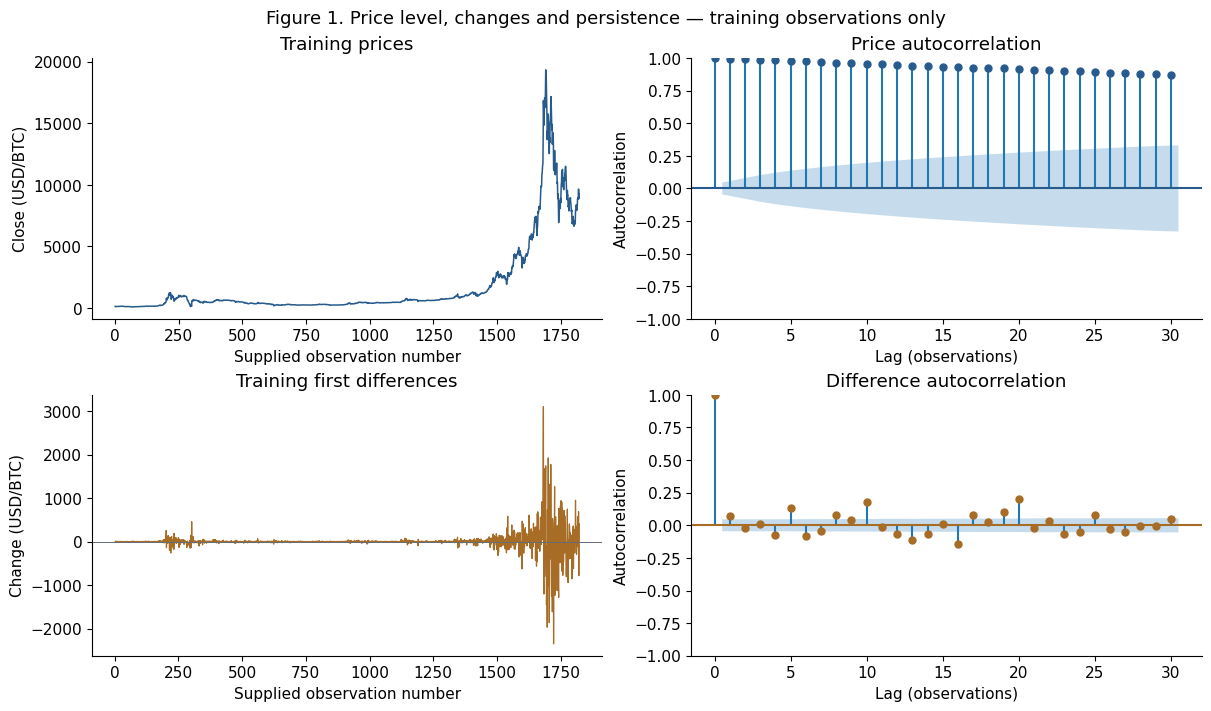

In [34]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'svg.fonttype': 'none'})
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
axes[0, 0].plot(np.arange(1, len(y_train) + 1), y_train, color='#285B8D', linewidth=1.1)
axes[0, 0].set(title='Training prices', xlabel='Supplied observation number', ylabel='Close (USD/BTC)')
axes[1, 0].plot(np.arange(2, len(y_train) + 1), delta_train, color='#A76C26', linewidth=0.9)
axes[1, 0].axhline(0, color='#646C76', linewidth=0.7)
axes[1, 0].set(title='Training first differences', xlabel='Supplied observation number', ylabel='Change (USD/BTC)')
plot_acf(y_train, lags=30, ax=axes[0, 1], title='Price autocorrelation', color='#285B8D')
plot_acf(delta_train, lags=30, ax=axes[1, 1], title='Difference autocorrelation', color='#A76C26')
for ax in axes[:, 1]:
    ax.set(xlabel='Lag (observations)', ylabel='Autocorrelation')
fig.suptitle('Figure 1. Price level, changes and persistence — training observations only', fontsize=13)
fig.savefig(FIGURE_DIR / 'figure-1-diagnostics.svg', bbox_inches='tight')
plt.show()


In [35]:
p = diagnostics.iloc[0]
d = diagnostics.iloc[1]
display(Markdown(
    f"Tables 2a–2b and Figure 1 support differencing: the price ADF p-value is {p['ADF p-value']:.6e}, "
    f"whereas the difference p-value is {d['ADF p-value']:.6e}. At 5%, the first test does not reject "
    f"a unit root and the second rejects it. Lag-1 autocorrelation falls from {p['Lag-1 ACF']:.6f} "
    f"to {d['Lag-1 ACF']:.6f}. This is consistent with reduced persistence in the level."
))
display(Markdown(
    f"Differencing does not resolve every problem. The difference standard deviation rises from "
    f"{d['Early-half SD (USD/BTC)']:.6f} in its first half to {d['Late-half SD (USD/BTC)']:.6f} "
    "in its second half. These are descriptive sample standard deviations, not a formal variance test. "
    "I would therefore describe differences as a more suitable starting target, rather than claim "
    "that the entire differenced series is stationary or easier to predict. The timestamp issue also "
    "means that historical changes are measured between supplied observations."
))


Tables 2a–2b and Figure 1 support differencing: the price ADF p-value is 5.966439e-01, whereas the difference p-value is 1.309988e-09. At 5%, the first test does not reject a unit root and the second rejects it. Lag-1 autocorrelation falls from 0.995727 to 0.068442. This is consistent with reduced persistence in the level.

Differencing does not resolve every problem. The difference standard deviation rises from 33.333481 in its first half to 325.895831 in its second half. These are descriptive sample standard deviations, not a formal variance test. I would therefore describe differences as a more suitable starting target, rather than claim that the entire differenced series is stationary or easier to predict. The timestamp issue also means that historical changes are measured between supplied observations.

If an autoregressive model predicts changes, its output must be converted back to a price. A next-step change forecast of 100 from a last price of 9,000 implies a price forecast of 9,100:

$$
\hat P_{T+h\mid T}=P_T+\sum_{j=1}^{h}\widehat{\Delta P}_{T+j\mid T}.
$$

For Q2 and Q3, I fit ETS directly to the original training prices, as requested. The target-choice discussion in Q1 does not change those questions into differenced-price ETS models.


<a id="q2"></a>
## Q2. ETS without trend or seasonality

I use additive-error, level-only ETS, denoted ETS(A,N,N). This is simple exponential smoothing. It updates the current level $\ell_t$ by combining the latest observation with the previous level:

$$
\ell_t=\alpha P_t+(1-\alpha)\ell_{t-1},\qquad \hat P_{T+h\mid T}=\ell_T.
$$

The smoothing weight $\alpha$ is dimensionless. The level and price are measured in USD per BTC. A larger weight gives the latest price more influence. With $\alpha=0.5$, a previous level of 100 and a new price of 110 produce a level of 105. With no trend or seasonal state, all future point forecasts equal the final fitted level.

The model estimates its smoothing weight and initial level from the training observations. I use `initialization_method='estimated'` and a maximum of 10,000 optimizer iterations; the fitted optimizer reports convergence. The test prices are not passed to the fit.


In [36]:
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

ses_model = ETSModel(y_train, error='add', trend=None, seasonal=None,
                     initialization_method='estimated')
ses_fit = ses_model.fit(disp=False, maxiter=10000)
if not ses_fit.mle_retvals['converged']:
    raise RuntimeError('The level-only ETS fit did not converge.')
ses_forecast = np.asarray(ses_fit.forecast(steps=5), dtype=float)
ses_error = y_test - ses_forecast
ses_rmse = float(np.sqrt(np.mean(ses_error ** 2)))

ses_results = pd.DataFrame({
    'Date': test_btc['Date'].dt.strftime('%Y-%m-%d').to_numpy(),
    'Actual (USD/BTC)': y_test,
    'SES forecast (USD/BTC)': ses_forecast,
    'Error: actual - forecast (USD/BTC)': ses_error
})
display(ses_results.style.hide(axis='index').format({c: '{:.2f}' for c in ses_results.columns[1:]}))
print(f'Q2 RMSE (USD/BTC): {ses_rmse:.6f}')
print(f'Smoothing level alpha: {ses_fit.smoothing_level:.6f}')


Date,Actual (USD/BTC),SES forecast (USD/BTC),Error: actual - forecast (USD/BTC)
2018-04-26,8938.47,9282.08,-343.61
2018-04-27,9351.47,9282.08,69.39
2018-04-28,9407.04,9282.08,124.96
2018-04-29,9248.45,9282.08,-33.63
2018-04-30,9077.28,9282.08,-204.80


Q2 RMSE (USD/BTC): 190.562940
Smoothing level alpha: 0.999900


Table 3 gives one row per held-out observation. Positive errors mean underprediction; negative errors mean overprediction. RMSE uses all five errors and the unrounded forecasts:

$$
\mathrm{RMSE}=\sqrt{\frac{1}{5}\sum_{h=1}^{5}(P_{T+h}-\hat P_{T+h\mid T})^2}.
$$

The denominator is five test observations, rather than the number of fitted parameters or training rows. Squaring prevents positive and negative errors from cancelling and gives large errors more weight; the square root restores the original price unit. Errors of 3 and −4 would give $\sqrt{(9+16)/2}\approx3.535534$ in that unit. This metric is not the square root of MAE.


In [37]:
display(Markdown(
    f"The model forecasts {ses_forecast[0]:,.2f} USD/BTC for each of the five observations. "
    f"Its RMSE is {ses_rmse:.6f} USD/BTC. The estimated smoothing weight of "
    f"{ses_fit.smoothing_level:.6f} puts almost all weight on the latest observation. "
    f"The flat forecast is therefore close to the last training price of {y_train.iloc[-1]:,.2f}. "
    "This is the expected forecast shape for a model with no trend or seasonality."
))


The model forecasts 9,282.08 USD/BTC for each of the five observations. Its RMSE is 190.562940 USD/BTC. The estimated smoothing weight of 0.999900 puts almost all weight on the latest observation. The flat forecast is therefore close to the last training price of 9,282.12. This is the expected forecast shape for a model with no trend or seasonality.

<a id="q3"></a>
## Q3. ETS with an additive trend

I add an undamped additive trend, giving ETS(A,A,N), while retaining additive errors and no seasonality. The model now estimates both a level $\ell_t$ and a slope $b_t$. The slope is a price change per observation, so its contribution increases with the forecast horizon:

$$
\hat P_{T+h\mid T}=\ell_T+h b_T.
$$

For example, a level of 100 and slope of 2 imply forecasts of 102 and 104 for horizons one and two. The model can follow a local trend, but a trend estimated from past prices may point in the wrong direction for a short future interval. Both ETS models make their five forecasts at the end of 2018-04-25; neither is updated with test observations.


In [38]:
holt_model = ETSModel(y_train, error='add', trend='add', damped_trend=False,
                      seasonal=None, initialization_method='estimated')
holt_fit = holt_model.fit(disp=False, maxiter=10000)
if not holt_fit.mle_retvals['converged']:
    raise RuntimeError('The trend ETS fit did not converge.')
holt_forecast = np.asarray(holt_fit.forecast(steps=5), dtype=float)
holt_error = y_test - holt_forecast
holt_rmse = float(np.sqrt(np.mean(holt_error ** 2)))

comparison = pd.DataFrame({
    'Date': test_btc['Date'].dt.strftime('%Y-%m-%d').to_numpy(),
    'Actual (USD/BTC)': y_test,
    'SES (USD/BTC)': ses_forecast,
    'Holt (USD/BTC)': holt_forecast,
    'Holt error (USD/BTC)': holt_error
})
display(comparison.style.hide(axis='index').format({c: '{:.2f}' for c in comparison.columns[1:]}))
model_scores = pd.DataFrame({
    'Model': ['ETS(A,N,N): SES', 'ETS(A,A,N): Holt'],
    'Test observations': [len(y_test), len(y_test)],
    'RMSE (USD/BTC)': [ses_rmse, holt_rmse],
    'MAE (USD/BTC)': [np.mean(np.abs(ses_error)), np.mean(np.abs(holt_error))]
})
display(model_scores.style.hide(axis='index').format({'RMSE (USD/BTC)': '{:.6f}', 'MAE (USD/BTC)': '{:.6f}'}))
print(f'Final Holt level (USD/BTC): {holt_fit.level.iloc[-1]:.6f}')
print(f'Final Holt slope (USD/BTC per observation): {holt_fit.slope.iloc[-1]:.6f}')
print(f'Holt smoothing level alpha: {holt_fit.smoothing_level:.6f}')
print(f'Holt smoothing trend beta: {holt_fit.smoothing_trend:.6f}')


Date,Actual (USD/BTC),SES (USD/BTC),Holt (USD/BTC),Holt error (USD/BTC)
2018-04-26,8938.47,9282.08,9287.15,-348.68
2018-04-27,9351.47,9282.08,9292.22,59.25
2018-04-28,9407.04,9282.08,9297.29,109.75
2018-04-29,9248.45,9282.08,9302.37,-53.92
2018-04-30,9077.28,9282.08,9307.44,-230.16


Model,Test observations,RMSE (USD/BTC),MAE (USD/BTC)
"ETS(A,N,N): SES",5,190.562940,155.277832
"ETS(A,A,N): Holt",5,196.475103,160.349498


Final Holt level (USD/BTC): 9282.079661
Final Holt slope (USD/BTC per observation): 5.071565
Holt smoothing level alpha: 0.999900
Holt smoothing trend beta: 0.000100


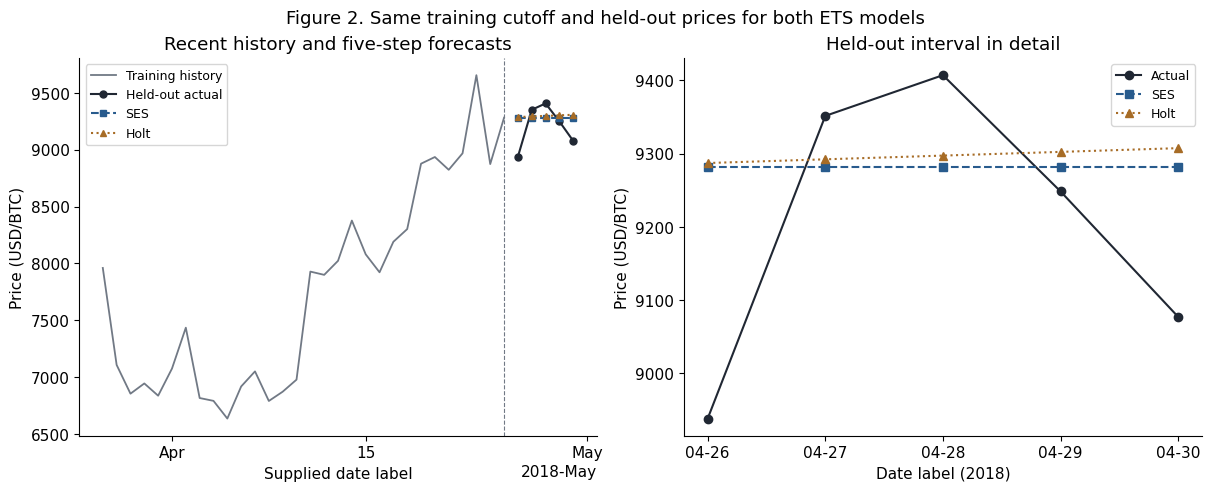

In [39]:
import matplotlib.dates as mdates

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
recent = train_btc.iloc[-30:]
axes[0].plot(recent['Date'], recent['Close'], color='#717985', label='Training history', linewidth=1.3)
axes[0].plot(test_btc['Date'], y_test, 'o-', color='#202733', label='Held-out actual', markersize=5)
axes[0].plot(test_btc['Date'], ses_forecast, 's--', color='#285B8D', label='SES', markersize=4)
axes[0].plot(test_btc['Date'], holt_forecast, '^:', color='#A76C26', label='Holt', markersize=5)
axes[0].axvline(train_btc['Date'].iloc[-1], color='#717985', linestyle='--', linewidth=0.8)
axes[0].set(title='Recent history and five-step forecasts', xlabel='Supplied date label', ylabel='Price (USD/BTC)')
axes[0].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=5))
axes[0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(axes[0].xaxis.get_major_locator()))
axes[0].legend(fontsize=9, loc='upper left')
axes[1].plot(test_btc['Date'], y_test, 'o-', color='#202733', label='Actual')
axes[1].plot(test_btc['Date'], ses_forecast, 's--', color='#285B8D', label='SES')
axes[1].plot(test_btc['Date'], holt_forecast, '^:', color='#A76C26', label='Holt')
axes[1].set(title='Held-out interval in detail', xlabel='Date label (2018)', ylabel='Price (USD/BTC)')
axes[1].xaxis.set_major_locator(mdates.DayLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
axes[1].legend(fontsize=9)
fig.suptitle('Figure 2. Same training cutoff and held-out prices for both ETS models', fontsize=13)
fig.savefig(FIGURE_DIR / 'figure-2-forecasts.svg', bbox_inches='tight')
plt.show()


In [40]:
rmse_gap = holt_rmse - ses_rmse
gap_percent = 100 * rmse_gap / ses_rmse
display(Markdown(
    f"Tables 4–5 show that SES has the lower RMSE: {ses_rmse:.6f}, compared with "
    f"{holt_rmse:.6f} for Holt. Adding the trend raises RMSE by {rmse_gap:.6f} USD/BTC "
    f"({gap_percent:.6f}% relative to SES). Holt forecasts rise from {holt_forecast[0]:,.2f} "
    f"to {holt_forecast[-1]:,.2f}, because its final slope is {holt_fit.slope.iloc[-1]:.6f} "
    "USD/BTC per observation. Figure 2 shows that this rising path does not match the five "
    "held-out prices closely enough to improve the aggregate squared error."
))
display(Markdown(
    "For this particular five-observation comparison, I would prefer SES: it has lower RMSE "
    "with fewer components. The fitted trend's upward extrapolation increases overprediction "
    "on low-price days, although it can help on days above the level forecast. A long-run "
    "increase in Bitcoin prices is therefore insufficient reason to prefer a trend for this "
    "short interval. Five errors provide limited evidence, and selecting a preferred model "
    "after seeing this required comparison does not make the same interval an independent "
    "confirmation of future superiority. Q4 proposes a broader one-step comparison."
))


Tables 4–5 show that SES has the lower RMSE: 190.562940, compared with 196.475103 for Holt. Adding the trend raises RMSE by 5.912164 USD/BTC (3.102473% relative to SES). Holt forecasts rise from 9,287.15 to 9,307.44, because its final slope is 5.071565 USD/BTC per observation. Figure 2 shows that this rising path does not match the five held-out prices closely enough to improve the aggregate squared error.

For this particular five-observation comparison, I would prefer SES: it has lower RMSE with fewer components. The fitted trend's upward extrapolation increases overprediction on low-price days, although it can help on days above the level forecast. A long-run increase in Bitcoin prices is therefore insufficient reason to prefer a trend for this short interval. Five errors provide limited evidence, and selecting a preferred model after seeing this required comparison does not make the same interval an independent confirmation of future superiority. Q4 proposes a broader one-step comparison.

<a id="q4"></a>
## Q4. Design of a rolling next-day evaluation

I would use an expanding training window and a rolling forecast origin. Each forecast is made with information available at that origin, and the newly observed price is added only after its prediction has been recorded. This is a method design, not an implemented backtest.

### Validation data and timing

Keep observations 1–1,822 as the development period and reserve observations 1,823–1,827 as a later test period. Within development, use observations 1–1,702 for the first fit and observations 1,703–1,822 as 120 ordered validation targets. This length is my proposed design choice, intended to cover more than the five targets used in Q2–Q3; it is not a teacher-specified requirement.

Table 6 illustrates the first two and final validation forecasts. Observation numbers are one-based, and each target is excluded from its training window.

| Forecast origin | Information available for fitting | One-step validation target |
|---|---|---|
| After observation 1,702 | Observations 1–1,702 | Observation 1,703 |
| After observation 1,703 | Observations 1–1,703 | Observation 1,704 |
| After observation 1,821 | Observations 1–1,821 | Observation 1,822 |

At each origin I would refit both fixed ETS specifications on exactly the same available prices, forecast one step, save both forecasts, then reveal the target. Repeat until there are 120 paired validation errors. Any preprocessing or parameter estimation must use only the available history. No random split or future interpolation is allowed.

The source has duplicate and missing date labels. A true calendar next-day evaluation first requires verified, uniquely dated daily observations from the provider; I would resolve ambiguous timestamps against the provider's records, and leave an unavailable target unscored for both models rather than invent it. On the uncorrected file, the proposed row-based calculation evaluates the next supplied observation, which cannot always be called the next calendar day. I have not repaired those dates or claimed a calendar-day backtest.

### Metrics and calculation

For model $m$ and validation target $t$, define the one-step error as:

$$
e_{m,t}=P_t-\hat P_{m,t\mid t-1}.
$$

With $V$ denoting the same set of eligible validation targets for both models and $N=|V|$, calculate:

$$
\mathrm{RMSE}_m=\sqrt{\frac{1}{N}\sum_{t\in V}e_{m,t}^2},\qquad
\mathrm{MAE}_m=\frac{1}{N}\sum_{t\in V}|e_{m,t}|.
$$

Both metrics have units of USD per BTC. Before date-eligibility exclusions, the proposed design has $N=120$; if any targets cannot be resolved, report their identities and the actual common $N$. RMSE gives more influence to large misses, while MAE describes the typical absolute miss more directly. For errors of 3 and −4, RMSE is approximately 3.535534 and MAE is 3.500000. I would aggregate the squared errors first and take one square root, rather than average a per-day “RMSE”, which would equal MAE.

### Model comparison and later testing

Compare SES, Holt and a naïve next-observation baseline on identical origins and targets. The rolling naïve forecast uses the latest price actually known at each origin. Rank by validation RMSE, report MAE alongside it, and inspect whether a few large errors or one price regime dominate the difference. Similar errors would favour the simpler model; this design alone does not establish a statistically significant difference.

If tuning additional settings, perform that choice inside earlier training history, or acknowledge that the 120-target score is a selection score. After fixing the model and rule, start at observation 1,822 and evaluate observations 1,823–1,827 sequentially, updating only when each true price becomes available. Report those five one-step errors separately. Because Q3 has already examined these five prices, such a reuse is an illustration rather than a newly untouched confirmation; genuinely fresh confirmation requires later unseen observations.

This rolling procedure differs from Q2–Q3. Their five forecasts share one origin and horizons one through five; the proposed rolling exercise has five different origins and horizon one each time. Their RMSE values answer different forecasting questions and should not be pooled or treated as directly comparable measures of model improvement.


<a id="appendix-a"></a>
## Appendix A. Does ETS improve on a simple benchmark?

A small RMSE gap between two ETS models does not show that either improves meaningfully over a simple rule. I therefore add a fixed-origin naïve benchmark, forecasting the last training price for all five horizons:

$$
\hat P_{T+h\mid T}^{\mathrm{naive}}=P_T,\quad h=1,\ldots,5.
$$

All five benchmark predictions use information available on 2018-04-25. Unlike the rolling baseline in Q4, this benchmark cannot use any actual test price to predict the next test observation.


In [41]:
naive_forecast = np.repeat(y_train.iloc[-1], len(y_test))
naive_error = y_test - naive_forecast
naive_rmse = float(np.sqrt(np.mean(naive_error ** 2)))
benchmark = pd.DataFrame({
    'Model': ['Naive, fixed origin', 'SES', 'Holt'],
    'RMSE (USD/BTC)': [naive_rmse, ses_rmse, holt_rmse],
    'MAE (USD/BTC)': [np.mean(np.abs(naive_error)), np.mean(np.abs(ses_error)), np.mean(np.abs(holt_error))]
})
display(benchmark.style.hide(axis='index').format({'RMSE (USD/BTC)': '{:.6f}', 'MAE (USD/BTC)': '{:.6f}'}))
ses_gain = naive_rmse - ses_rmse
display(Markdown(
    f"Table A1 shows naïve RMSE of {naive_rmse:.6f} and SES RMSE of {ses_rmse:.6f}. "
    f"The SES improvement is only {ses_gain:.6f} USD/BTC "
    f"({100 * ses_gain / naive_rmse:.6f}% relative to the benchmark). "
    "The near-boundary smoothing weight explains the similarity: SES behaves almost like "
    "repeating the latest price. The result supports SES over Holt in this short comparison, "
    "but provides little evidence of a useful gain over the simple benchmark. No significance "
    "or trading-profit claim follows from five forecast errors."
))


Model,RMSE (USD/BTC),MAE (USD/BTC)
"Naive, fixed origin",190.579561,155.286000
SES,190.562940,155.277832
Holt,196.475103,160.349498


Table A1 shows naïve RMSE of 190.579561 and SES RMSE of 190.562940. The SES improvement is only 0.016622 USD/BTC (0.008722% relative to the benchmark). The near-boundary smoothing weight explains the similarity: SES behaves almost like repeating the latest price. The result supports SES over Holt in this short comparison, but provides little evidence of a useful gain over the simple benchmark. No significance or trading-profit claim follows from five forecast errors.

## References and software

1. IS6400, Week 8 Time series I_Tutorial_2026.ipynb, tutorial cells 0–48 and assignment/submission cells 49–50; supplied Q5BTC-USD.csv. [Canvas source](https://canvas.cityu.edu.hk/courses/71457/files/16311646).
2. Hyndman, R. J. and Athanasopoulos, G., Forecasting: Principles and Practice, third edition. [Stationarity and differencing](https://otexts.com/fpp3/arima.html#stationarity-and-differencing) and [time series cross-validation](https://otexts.com/fpp3/toolbox.html#time-series-cross-validation). Accessed 21 October 2026.
3. statsmodels, [ETSModel documentation](https://www.statsmodels.org/stable/generated/statsmodels.tsa.exponential_smoothing.ets.ETSModel.html). The installed version used for these calculations is reported below.

The Bitcoin models use estimated initialization, additive errors and no seasonality. Holt has an undamped additive trend. No random splitting, simulation, or test-based parameter search is used.


In [42]:
print(f'Python {platform.python_version()}')
print(f'pandas {pd.__version__}; NumPy {np.__version__}; SciPy {scipy.__version__}')
print(f'statsmodels {statsmodels.__version__}; scikit-learn {sklearn.__version__}')


Python 3.12.3
pandas 2.3.3; NumPy 1.26.4; SciPy 1.13.1
statsmodels 0.14.2; scikit-learn 1.5.1


I used OpenAI Codex to assist with this assignment.
